In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/mugdhanaik/phase2-step2/__notebook__.ipynb
/kaggle/input/notebooks/mugdhanaik/phase2-step2/__output__.json
/kaggle/input/notebooks/mugdhanaik/phase2-step2/__results__.html
/kaggle/input/notebooks/mugdhanaik/phase2-step2/conditions_meta.json
/kaggle/input/notebooks/mugdhanaik/phase2-step2/custom.css
/kaggle/input/notebooks/mugdhanaik/phase2-step2/encode_stats.csv
/kaggle/input/notebooks/mugdhanaik/phase2-step2/faces_manifest_B.csv
/kaggle/input/notebooks/mugdhanaik/phase2-step2/faces_manifest_D.csv
/kaggle/input/notebooks/mugdhanaik/phase2-step2/pair_samples.png
/kaggle/input/notebooks/mugdhanaik/phase2-step2/compressed_faces/faces_B/video_100_f0__B.jpg
/kaggle/input/notebooks/mugdhanaik/phase2-step2/compressed_faces/faces_B/video_100_f100__B.jpg
/kaggle/input/notebooks/mugdhanaik/phase2-step2/compressed_faces/faces_B/video_100_f10__B.jpg
/kaggle/input/notebooks/mugdhanaik/phase2-step2/compressed_faces/faces_B/video_100_f110__B.jpg
/kaggle/input/notebooks/mugdhan

In [2]:
import os, sys, json, time, hashlib, zipfile, copy
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import cv2
from PIL import Image

try:
    import timm
except ImportError:
    os.system("pip install -q --no-deps timm huggingface_hub safetensors")
    import timm

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
else:
    os.system(f"cd {REPO_DIR} && git pull")
sys.path.append(REPO_DIR)
import dfx_model, dfx_data

INPUT_ROOT = "/kaggle/input"
OUT = "/kaggle/working/p2_6"
CROPS = "/kaggle/working/crops"
os.makedirs(OUT, exist_ok=True); os.makedirs(CROPS, exist_ok=True)

BATCH_SIZE, NUM_WORKERS = 32, 2
SEED = 2026
UNIT_N = 32          # faces for the CAM equivalence unit test
SANITY_N = 300       # faces for the model-randomisation test
AGREE_MIN = 0.999    # fp32 vs Step 2.5 prediction agreement
SANITY_CORR_MAX = 0.5

def find_one(name, roots):
    for root in roots:
        matches = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"{name}: {len(matches)} copies under {root}. Attach only one:\n" + "\n".join(matches))
    raise FileNotFoundError(f"{name} not found under {roots}")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Set the Accelerator to GPU T4."
print("device:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| timm", timm.__version__)

Cloning into '/kaggle/working/repo'...


device: Tesla T4 | torch 2.11.0+cu130 | timm 1.0.30


In [3]:
# ============================================================
# LOAD MODEL, FROZEN THRESHOLD, MANIFEST (same integrity checks as Step 2.5)
# ============================================================
best_pt = find_one("best.pt", [INPUT_ROOT])
config_json = find_one("config.json", [INPUT_ROOT])
thr_json = find_one("threshold.json", [INPUT_ROOT])
config = json.load(open(config_json)); thr_info = json.load(open(thr_json))
assert not config.get("debug"), "config.json comes from a DEBUG run."
assert config["train_faces"] > 5000, "not the full training run"
THRESHOLD = float(thr_info["value"])
assert abs(THRESHOLD - 0.2217) < 5e-4, f"threshold {THRESHOLD} is not the frozen 0.2217"
MEAN, STD, SIZE = tuple(config["mean"]), tuple(config["std"]), dfx_model.INPUT_SIZE

manifest_csv = find_one("faces_manifest.csv", [INPUT_ROOT, REPO_DIR])
meta = json.load(open(find_one("manifest_meta.json", [INPUT_ROOT, REPO_DIR])))
assert sha256(manifest_csv) == meta["manifest_sha256"], "manifest does not match manifest_meta.json"
assert config["manifest_sha256"] == meta["manifest_sha256"], "model trained on a different manifest"

model, info = dfx_model.build_xception(pretrained=False)
dfx_model.load_checkpoint(model, best_pt, map_location=device)
model = model.to(device).eval()
for p in model.parameters():
    p.requires_grad_(False)

eval_meta = json.load(open(find_one("eval_meta.json", [INPUT_ROOT, REPO_DIR])))
assert eval_meta["model_sha256"] == sha256(best_pt), "Step 2.5 used a different checkpoint than the one attached now"
assert abs(eval_meta["threshold"] - THRESHOLD) < 1e-9, "Step 2.5 used a different threshold"
print(f"model OK | epoch {config['best_epoch']} | threshold {THRESHOLD:.4f} | manifest {meta['manifest_sha256'][:8]}")

model OK | epoch 8 | threshold 0.2217 | manifest 80eae250


In [4]:
# ============================================================
# LOCATE CROPS (folder or zip) AND BUILD CONDITION TABLES A, B, C, D
# ============================================================
def unzip_if_needed(zip_name):
    """If <zip_name> is attached as a zip, extract once to /kaggle/working/crops/<stem>. Returns a search base."""
    zips = [os.path.join(d, zip_name) for d, _, fs in os.walk(INPUT_ROOT) if zip_name in fs]
    if not zips:
        return None
    assert len(zips) == 1, f"{zip_name}: {len(zips)} copies attached: {zips}"
    dest = os.path.join(CROPS, zip_name.replace(".zip", ""))
    if not os.path.exists(os.path.join(dest, ".done")):
        t = time.time(); os.makedirs(dest, exist_ok=True)
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(dest)
        open(os.path.join(dest, ".done"), "w").close()
        print(f"unzipped {zip_name} in {time.time() - t:.0f}s")
    return dest

def find_crop_root(df, bases, label):
    sample = df["face_rel"].sample(min(12, len(df)), random_state=0).tolist()
    for base in bases:
        if base is None:
            continue
        for d, _, _ in os.walk(base):
            if all(os.path.exists(os.path.join(d, r)) for r in sample):
                print(f"{label}: crops under {d}")
                return d
    raise FileNotFoundError(f"{label}: no folder contains the sample crops (face_rel). Check the attached datasets.")

m = pd.read_csv(manifest_csv)
assert {"test_A", "test_C"} <= set(m["role"])
clean_df = {"A": m[m["role"] == "test_A"].reset_index(drop=True), "C": m[m["role"] == "test_C"].reset_index(drop=True)}
clean_zip = unzip_if_needed("step5_faces.zip")
comp_zip = unzip_if_needed("compressed_faces.zip")
clean_root = find_crop_root(pd.concat(clean_df.values()),
                            ["/kaggle/input/notebooks/mugdhanaik/step5-regenerate/step5_faces", clean_zip, INPUT_ROOT],
                            "clean crops")

cond = {}
for k in "AC":
    cond[k] = {"df": clean_df[k], "root": clean_root, "name": {"A": "A: FF++ test (clean)", "C": "C: Celeb-DF test (clean)"}[k]}
for k, c in (("B", "A"), ("D", "C")):
    dfk = pd.read_csv(find_one(f"faces_manifest_{k}.csv", [INPUT_ROOT, REPO_DIR]))
    assert len(dfk) == len(cond[c]["df"]), f"{k}: row count differs from {c}"
    assert set(dfk["pair_id"]) <= set(cond[c]["df"]["face_id"]), f"{k}: pair_id does not point to clean faces"
    cond[k] = {"df": dfk, "root": None, "name": {"B": "B: FF++ test (compressed)", "D": "D: Celeb-DF test (compressed)"}[k]}
comp_root = find_crop_root(pd.concat([cond["B"]["df"], cond["D"]["df"]]), [comp_zip, INPUT_ROOT], "compressed crops")
cond["B"]["root"] = cond["D"]["root"] = comp_root

pred25 = {}
for k in "ABCD":
    pr = pd.read_csv(find_one(f"predictions_{k}.csv", [INPUT_ROOT, REPO_DIR]))
    assert set(pr["face_id"]) == set(cond[k]["df"]["face_id"]), f"{k}: Step 2.5 predictions do not match this manifest"
    pred25[k] = pr.set_index("face_id")
rows = [{"cond": k, "faces": len(cond[k]["df"]), "videos": cond[k]["df"]["video_id"].nunique()} for k in "ABCD"]
print(pd.DataFrame(rows).to_string(index=False))

clean crops: crops under /kaggle/input/notebooks/mugdhanaik/step5-regenerate/step5_faces
compressed crops: crops under /kaggle/input/notebooks/mugdhanaik/phase2-step2/compressed_faces
cond  faces  videos
   A   5883     198
   B   5883     198
   C   8763     300
   D   8763     300


In [5]:
# ============================================================
# GRAD-CAM (own implementation). Features = model.act4 output (2048 x 10 x 10); gradient flows through the head only.
# Target = the model's PREDICTED class at the frozen threshold: +logit for FAKE, -logit for REAL.
# ============================================================
assert hasattr(model, "act4") and hasattr(model, "forward_features") and hasattr(model, "forward_head")
fc = model.get_classifier()
assert isinstance(fc, nn.Linear) and fc.out_features == 1, "expected a single linear output layer"
_act = {}
model.act4.register_forward_hook(lambda mod, inp, out: _act.__setitem__("a", out.detach()))

def gradcam_batch(net, x, thr, target=None):
    """Returns raw CAM (B,10,10, >=0), prob (B,), target (B,) in {-1,+1}, features, logit. fp32 throughout."""
    with torch.no_grad():
        feats = net.forward_features(x)
    feats = feats.detach().requires_grad_(True)
    logit = net.forward_head(feats).reshape(-1)
    prob = torch.sigmoid(logit.detach())
    tgt = ((prob >= thr).float() * 2 - 1) if target is None else target
    score = (tgt * logit).sum()
    grad = torch.autograd.grad(score, feats)[0]
    w = grad.mean(dim=(2, 3))
    cam = torch.relu((w[:, :, None, None] * feats.detach()).sum(1))
    return cam, prob, tgt, feats.detach(), logit.detach()

def normalise(cam):
    """Per-image max normalisation to [0,1]. Returns (cam_n, raw_max, empty)."""
    mx = cam.amax(dim=(1, 2))
    empty = mx <= 1e-12
    cam_n = cam / mx.clamp_min(1e-12)[:, None, None]
    cam_n[empty] = 0
    return cam_n, mx, empty

def loader_for(df, root, bs=BATCH_SIZE):
    return dfx_data.make_loader(df, root, MEAN, STD, SIZE, train=False, batch_size=bs, num_workers=NUM_WORKERS)

def cam_stats(c):
    """c: (N,10,10) normalised maps. Entropy (0..1), centre of mass (0..1), central-6x6 share, peak share."""
    N = len(c); flat = c.reshape(N, -1); s = flat.sum(1); ok = s > 1e-12
    p = np.zeros_like(c, dtype=float); p[ok] = c[ok] / s[ok, None, None]
    ent = -(p * np.log(p + 1e-12)).reshape(N, -1).sum(1) / np.log(100)
    yy, xx = np.mgrid[0:10, 0:10]; yy = (yy + 0.5) / 10; xx = (xx + 0.5) / 10
    out = pd.DataFrame({"entropy": ent, "com_y": (p * yy).reshape(N, -1).sum(1), "com_x": (p * xx).reshape(N, -1).sum(1),
                        "central_share": p[:, 2:8, 2:8].reshape(N, -1).sum(1), "peak_share": p.reshape(N, -1).max(1)})
    out.loc[~ok, :] = np.nan
    return out
print("Grad-CAM functions ready. act4 hook registered.")

Grad-CAM functions ready. act4 hook registered.


In [6]:
# ============================================================
# UNIT TESTS (stop on failure): (1) hook output == forward_features, (2) Grad-CAM == classic CAM for this head
# ============================================================
sub = cond["A"]["df"].sample(UNIT_N, random_state=SEED).reset_index(drop=True)
x, y, fid = next(iter(loader_for(sub, cond["A"]["root"], UNIT_N)))
x = x.to(device)
with torch.no_grad():
    _ = model(x)
hook_feats = _act["a"]
cam, prob, tgt, feats, logit = gradcam_batch(model, x, THRESHOLD)
t1 = bool(torch.allclose(hook_feats, feats, atol=1e-5))
print("hook on model.act4 matches forward_features:", t1, "| feature shape", tuple(feats.shape))

w_cls = (tgt[:, None] * fc.weight[0][None, :])
cam_classic = torch.relu((w_cls[:, :, None, None] * feats).sum(1))
cam_scaled = cam * (feats.shape[2] * feats.shape[3])        # grad = weight / (H*W)
rel_err = float((cam_scaled - cam_classic).abs().max() / cam_classic.abs().max().clamp_min(1e-12))
a_n, _, _ = normalise(cam); b_n, _, _ = normalise(cam_classic)
norm_err = float((a_n - b_n).abs().max())
t2 = rel_err < 1e-4 and norm_err < 1e-4
print(f"Grad-CAM vs classic CAM: relative error {rel_err:.2e}, normalised error {norm_err:.2e} -> {t2}")
assert feats.shape[2:] == (10, 10), f"expected 10x10 maps, got {tuple(feats.shape[2:])}"
assert t1 and t2, "UNIT TEST FAILED: do not continue. Tell Mugdha/Claude."
unit_test = {"hook_matches_forward_features": t1, "cam_equals_classic_cam": t2, "rel_err": rel_err, "norm_err": norm_err, "n_faces": UNIT_N}
print("UNIT TESTS PASSED")

hook on model.act4 matches forward_features: True | feature shape (32, 2048, 10, 10)
Grad-CAM vs classic CAM: relative error 1.42e-07, normalised error 1.79e-07 -> True
UNIT TESTS PASSED


In [7]:
# ============================================================
# GENERATE CAMS FOR EVERY FACE IN A, B, C, D
# ============================================================
all_stats, cam_store = [], {}
for k in "ABCD":
    df, root = cond[k]["df"], cond[k]["root"]
    ids, cams, rmax, probs, tgts, empties = [], [], [], [], [], []
    t0 = time.time()
    for x, y, fid in loader_for(df, root):
        cam, prob, tgt, _, _ = gradcam_batch(model, x.to(device), THRESHOLD)
        cam_n, mx, empty = normalise(cam)
        ids += list(fid); cams.append(cam_n.cpu().numpy()); rmax.append(mx.cpu().numpy())
        probs.append(prob.cpu().numpy()); tgts.append(tgt.cpu().numpy()); empties.append(empty.cpu().numpy())
    cams = np.concatenate(cams); rmax = np.concatenate(rmax); probs = np.concatenate(probs)
    tgts = np.concatenate(tgts); empties = np.concatenate(empties)
    assert len(ids) == len(df) and len(set(ids)) == len(df) and set(ids) == set(df["face_id"]), f"{k}: maps do not match manifest"
    np.savez_compressed(os.path.join(OUT, f"cams_{k}.npz"), face_id=np.array(ids), cam=cams.astype(np.float32),
                        raw_max=rmax.astype(np.float32), prob=probs.astype(np.float32), target=tgts.astype(np.int8))
    st = cam_stats(cams); st.insert(0, "face_id", ids); st.insert(1, "cond", k)
    st["raw_max"] = rmax; st["empty"] = empties; st["prob_fp32"] = probs; st["target"] = tgts
    p25 = pred25[k].loc[ids]
    st["prob_2_5"] = p25["prob_fake"].to_numpy(); st["pred_2_5"] = p25["pred"].to_numpy(); st["outcome"] = p25["outcome"].to_numpy()
    st["video_id"] = p25["video_id"].to_numpy()
    st["pred_fp32"] = (probs >= THRESHOLD).astype(int); st["agrees_2_5"] = st["pred_fp32"] == st["pred_2_5"]
    all_stats.append(st); cam_store[k] = {"ids": np.array(ids), "cam": cams}
    print(f"{k}: {len(ids)} maps | empty {empties.mean() * 100:.2f}% | fp32 agrees with 2.5 on {st['agrees_2_5'].mean() * 100:.2f}% | {time.time() - t0:.0f}s")
face_stats = pd.concat(all_stats, ignore_index=True)
face_stats.to_csv(os.path.join(OUT, "cam_face_stats.csv"), index=False)

STAT_COLS = ["entropy", "com_y", "com_x", "central_share", "peak_share"]
def summarise(g):
    r = {"n_faces": len(g), "n_videos": g["video_id"].nunique(), "empty_share": g["empty"].mean()}
    r.update({c: g[c].mean() for c in STAT_COLS}); return pd.Series(r)
by_out = face_stats.groupby(["cond", "outcome"]).apply(summarise).reset_index()
by_all = face_stats.groupby("cond").apply(summarise).reset_index().assign(outcome="ALL")
cam_summary = pd.concat([by_all, by_out], ignore_index=True)
cam_summary.to_csv(os.path.join(OUT, "cam_summary.csv"), index=False)
print(cam_summary.round(3).to_string(index=False))

A: 5883 maps | empty 0.00% | fp32 agrees with 2.5 on 99.95% | 121s
B: 5883 maps | empty 0.00% | fp32 agrees with 2.5 on 99.86% | 123s
C: 8763 maps | empty 0.00% | fp32 agrees with 2.5 on 99.75% | 183s
D: 8763 maps | empty 0.01% | fp32 agrees with 2.5 on 99.75% | 184s
cond  n_faces  n_videos  empty_share  entropy  com_y  com_x  central_share  peak_share outcome
   A   5883.0     198.0        0.000    0.783  0.573  0.502          0.776       0.062     ALL
   B   5883.0     198.0        0.000    0.827  0.540  0.478          0.732       0.054     ALL
   C   8763.0     300.0        0.000    0.757  0.549  0.531          0.795       0.071     ALL
   D   8763.0     300.0        0.000    0.799  0.528  0.512          0.721       0.065     ALL
   A    632.0      59.0        0.000    0.824  0.548  0.447          0.606       0.057      FN
   A    317.0      50.0        0.000    0.690  0.553  0.530          0.819       0.093      FP
   A   2566.0      96.0        0.000    0.822  0.571  0.481        

/tmp/ipykernel_23/1164246263.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_out = face_stats.groupby(["cond", "outcome"]).apply(summarise).reset_index()
/tmp/ipykernel_23/1164246263.py:35: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_all = face_stats.groupby("cond").apply(summarise).reset_index().assign(outcome="ALL")


In [8]:
# ============================================================
# SANITY TEST: randomise the last layers; maps must change (mean correlation < 0.5)
# Same target class as the real model, so only the weights differ.
# ============================================================
rnd = copy.deepcopy(model)
torch.manual_seed(SEED)
for mod in rnd.get_classifier().modules():
    if hasattr(mod, "reset_parameters"): mod.reset_parameters()
if hasattr(rnd, "conv4"):
    for mod in rnd.conv4.modules():
        if hasattr(mod, "reset_parameters"): mod.reset_parameters()
rnd = rnd.to(device).eval()
for p in rnd.parameters(): p.requires_grad_(False)

rows = []
for k in ("A", "C"):
    sub = cond[k]["df"].sample(SANITY_N // 2, random_state=SEED).reset_index(drop=True)
    for x, y, fid in loader_for(sub, cond[k]["root"]):
        x = x.to(device)
        c0, _, tg, _, _ = gradcam_batch(model, x, THRESHOLD)
        c1, _, _, _, _ = gradcam_batch(rnd, x, THRESHOLD, target=tg)
        n0, _, e0 = normalise(c0); n1, _, e1 = normalise(c1)
        for i, f in enumerate(fid):
            a, b = n0[i].flatten().cpu().numpy(), n1[i].flatten().cpu().numpy()
            r = np.nan if (a.std() < 1e-9 or b.std() < 1e-9) else float(np.corrcoef(a, b)[0, 1])
            rows.append({"face_id": f, "cond": k, "pearson": r, "orig_empty": bool(e0[i]), "rand_empty": bool(e1[i])})
san = pd.DataFrame(rows); san.to_csv(os.path.join(OUT, "sanity_randomization.csv"), index=False)
mean_r = float(san["pearson"].mean()); n_valid = int(san["pearson"].notna().sum())
sanity_pass = bool(mean_r < SANITY_CORR_MAX)
print(f"randomised-vs-trained map correlation: mean {mean_r:.3f} over {n_valid} faces (limit {SANITY_CORR_MAX}) -> {'PASS' if sanity_pass else 'FAIL'}")
del rnd; torch.cuda.empty_cache()

randomised-vs-trained map correlation: mean 0.095 over 300 faces (limit 0.5) -> PASS


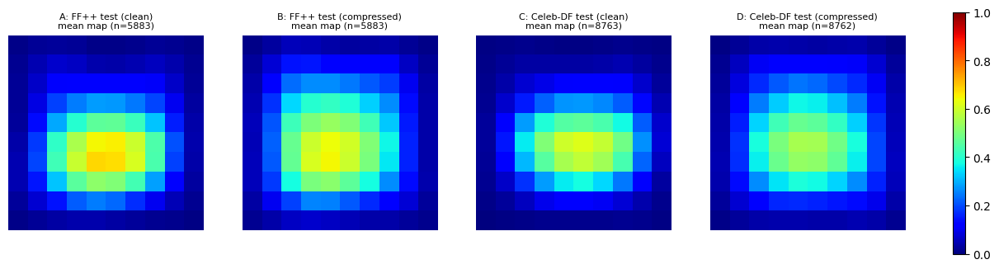

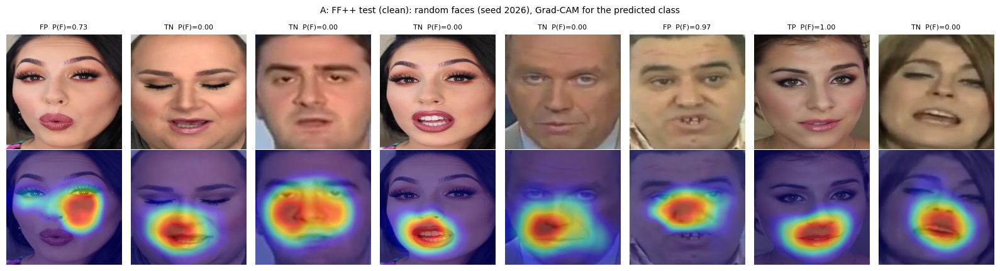

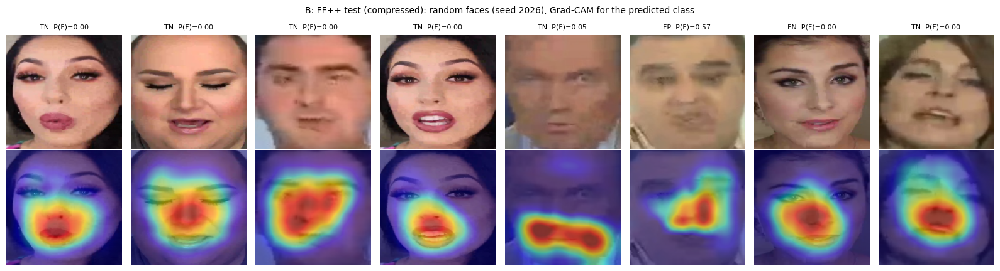

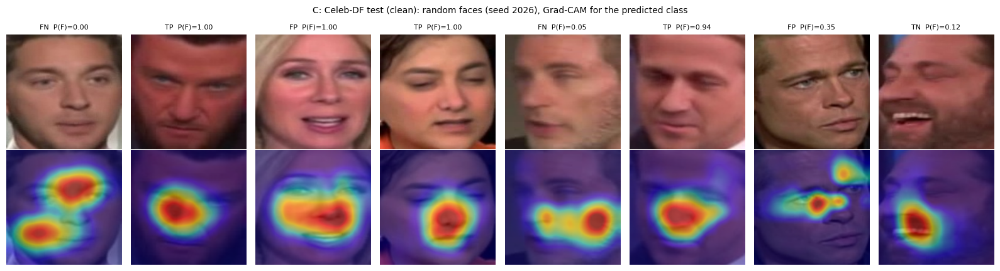

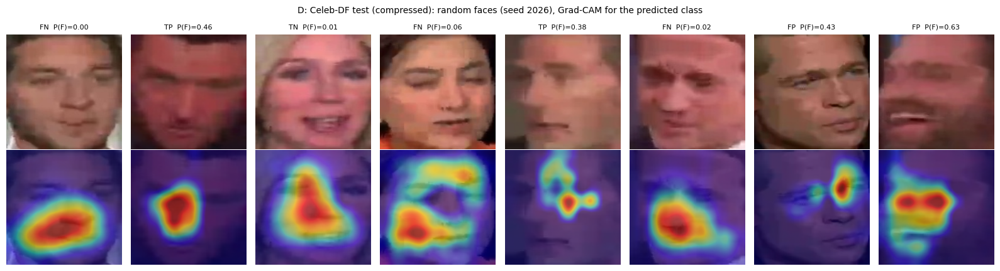

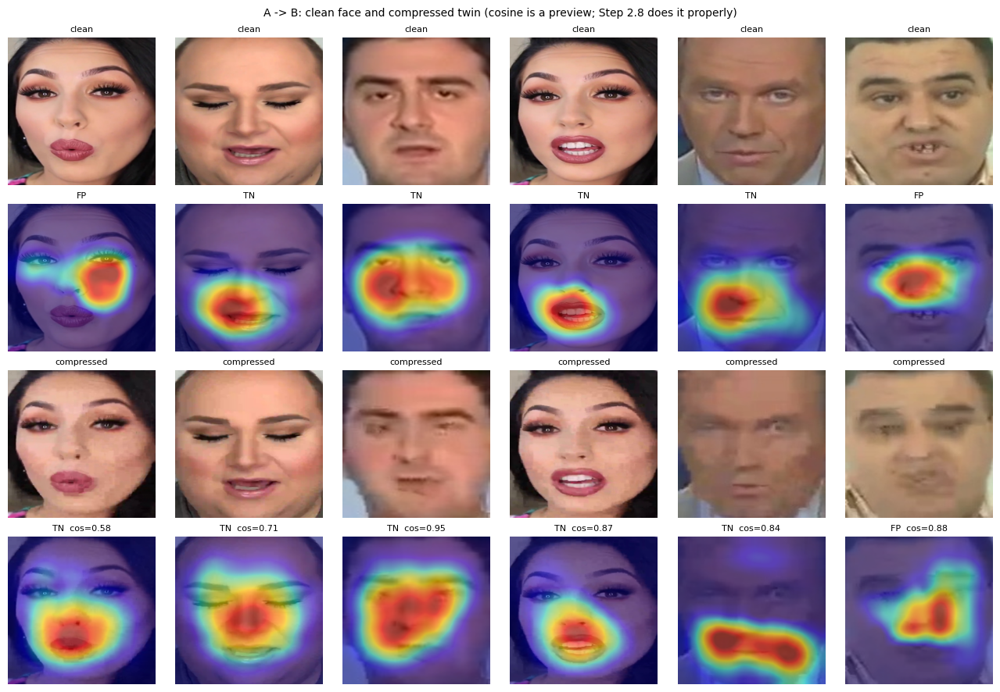

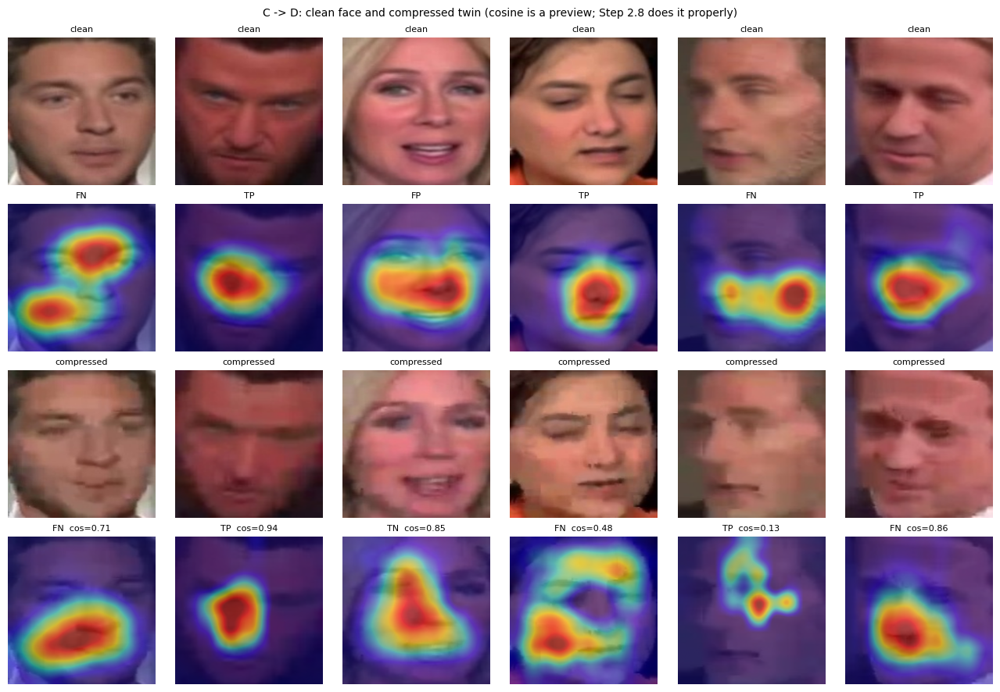

In [9]:
# ============================================================
# FIGURES: mean heatmaps, examples (fixed seed, not hand-picked), clean/compressed twins
# ============================================================
def load_img(root, rel):
    im = Image.open(os.path.join(root, rel)).convert("RGB").resize((299, 299))
    return np.asarray(im)

def overlay(img, cam, alpha=0.5):
    up = np.clip(cv2.resize(cam.astype(np.float32), (299, 299), interpolation=cv2.INTER_CUBIC), 0, 1)
    heat = plt.cm.jet(up)[..., :3]
    return np.clip((1 - alpha) * img / 255.0 + alpha * heat, 0, 1)

def cam_of(k, face_id):
    i = int(np.where(cam_store[k]["ids"] == face_id)[0][0]); return cam_store[k]["cam"][i]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, k in zip(axes, "ABCD"):
    c = cam_store[k]["cam"]; keep = c.reshape(len(c), -1).max(1) > 0
    im = ax.imshow(c[keep].mean(0), cmap="jet", vmin=0, vmax=1); ax.set_title(f"{cond[k]['name']}\nmean map (n={int(keep.sum())})", fontsize=8); ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.015); plt.savefig(os.path.join(OUT, "mean_heatmaps.png"), dpi=130, bbox_inches="tight"); plt.show()

for k in "ABCD":
    df = cond[k]["df"].sample(8, random_state=SEED)
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
    for j, (_, r) in enumerate(df.iterrows()):
        img = load_img(cond[k]["root"], r["face_rel"]); pr = pred25[k].loc[r["face_id"]]
        axes[0, j].imshow(img); axes[0, j].set_title(f"{pr['outcome']}  P(F)={pr['prob_fake']:.2f}", fontsize=8)
        axes[1, j].imshow(overlay(img, cam_of(k, r["face_id"])))
        for a in (axes[0, j], axes[1, j]): a.axis("off")
    fig.suptitle(f"{cond[k]['name']}: random faces (seed {SEED}), Grad-CAM for the predicted class", fontsize=10)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f"gradcam_examples_{k}.png"), dpi=120); plt.show()

for clean_k, comp_k in (("A", "B"), ("C", "D")):
    cdf = cond[clean_k]["df"].set_index("face_id"); pairs = cond[comp_k]["df"].sample(6, random_state=SEED)
    fig, axes = plt.subplots(4, 6, figsize=(13, 9))
    for j, (_, r) in enumerate(pairs.iterrows()):
        cf = r["pair_id"]; a, b = cam_of(clean_k, cf), cam_of(comp_k, r["face_id"])
        i1 = load_img(cond[clean_k]["root"], cdf.loc[cf, "face_rel"]); i2 = load_img(cond[comp_k]["root"], r["face_rel"])
        cs = float((a.flatten() @ b.flatten()) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))
        for row, im_, tt in ((0, i1, "clean"), (1, overlay(i1, a), f"{pred25[clean_k].loc[cf, 'outcome']}"), (2, i2, "compressed"),
                              (3, overlay(i2, b), f"{pred25[comp_k].loc[r['face_id'], 'outcome']}  cos={cs:.2f}")):
            axes[row, j].imshow(im_); axes[row, j].set_title(tt, fontsize=8); axes[row, j].axis("off")
    fig.suptitle(f"{clean_k} -> {comp_k}: clean face and compressed twin (cosine is a preview; Step 2.8 does it properly)", fontsize=10)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f"gradcam_twins_{clean_k}_{comp_k}.png"), dpi=110); plt.show()

In [10]:
# ============================================================
# CHECKS TABLE + METADATA (send cam_checks.csv, unit-test and sanity lines, cam_summary.csv back)
# ============================================================
agree = face_stats.groupby("cond")["agrees_2_5"].mean()
empty = face_stats.groupby("cond")["empty"].mean()

MARGIN = 0.03   # all observed flips are within 0.015 of THRESHOLD
AGREE_MIN = 0.995
fs = face_stats.copy()
far = fs[((fs["prob_fp32"] - THRESHOLD).abs() > MARGIN) & ((fs["prob_2_5"] - THRESHOLD).abs() > MARGIN)]
far_agree = far.groupby("cond")["agrees_2_5"].mean()
checks = [{"check": "unit test: hook == forward_features", "value": unit_test["hook_matches_forward_features"], "limit": "True", "pass": unit_test["hook_matches_forward_features"]},
          {"check": "unit test: Grad-CAM == classic CAM", "value": f"rel_err {unit_test['rel_err']:.2e}", "limit": "< 1e-4", "pass": unit_test["cam_equals_classic_cam"]},
          {"check": "feature map size", "value": "10x10", "limit": "10x10", "pass": True},
          {"check": "randomisation sanity: mean correlation", "value": round(mean_r, 3), "limit": f"< {SANITY_CORR_MAX}", "pass": sanity_pass}]
for k in "ABCD":
    n_ok = len(cam_store[k]["ids"]) == len(cond[k]["df"])
    checks.append({"check": f"{k}: one map per face", "value": len(cam_store[k]["ids"]), "limit": len(cond[k]["df"]), "pass": n_ok})
    checks.append({"check": f"{k}: fp32 prediction agrees with Step 2.5", "value": round(float(agree[k]), 5),
                   "limit": f">= {AGREE_MIN} and 100% outside +-{MARGIN} of threshold",
                   "pass": bool(agree[k] >= AGREE_MIN and far_agree[k] == 1.0)})
    checks.append({"check": f"{k}: share of empty maps", "value": round(float(empty[k]), 4), "limit": "report (informational)", "pass": True})
checks = pd.DataFrame(checks); checks.to_csv(os.path.join(OUT, "cam_checks.csv"), index=False)
print(checks.to_string(index=False))

import json
manifest_meta = json.load(open("/kaggle/input/datasets/mugdhanaik/manifestedfile/manifest_meta.json"))

gmeta = {"created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
         "model_sha256": sha256(best_pt), "manifest_sha256": manifest_meta["manifest_sha256"], "threshold": THRESHOLD,
         # ... rest unchanged ...
         "target_class": "predicted class at the frozen threshold (+logit for FAKE, -logit for REAL)", "layer": "model.act4 (2048 x 10 x 10)",
         "normalisation": "per-image max; raw_max saved; empty maps stored as zeros", "stats": {"central_region": "cells 2..7 on both axes (6x6 of 10x10)", "entropy": "natural log / ln(100)"},
         "seed": SEED,"agree_note": "residual disagreements (<=0.45%) are near-threshold fp16-vs-fp32 flips, all within 0.015 of THRESHOLD; faces further out agree 100%", "unit_test": unit_test, "sanity_mean_corr": mean_r, "torch": torch.__version__, "timm": timm.__version__,
         "limitation": "For global average pooling + one linear layer, Grad-CAM equals classic CAM; maps are coarse (10x10) and channel weights do not depend on the image."}
json.dump(gmeta, open(os.path.join(OUT, "gradcam_meta.json"), "w"), indent=2)
print("\nsaved:", sorted(os.listdir(OUT)))
assert checks["pass"].all(), "A CHECK FAILED: do not start Step 2.7 until this is understood."
print("ALL CHECKS PASSED. Next: Step 2.7 faithfulness. Do NOT retrain or change the threshold.")

                                  check            value                                         limit  pass
    unit test: hook == forward_features             True                                          True  True
     unit test: Grad-CAM == classic CAM rel_err 1.42e-07                                        < 1e-4  True
                       feature map size            10x10                                         10x10  True
 randomisation sanity: mean correlation            0.095                                         < 0.5  True
                    A: one map per face             5883                                          5883  True
A: fp32 prediction agrees with Step 2.5          0.99949 >= 0.995 and 100% outside +-0.03 of threshold  True
                 A: share of empty maps              0.0                        report (informational)  True
                    B: one map per face             5883                                          5883  True
B: fp32 prediction 